In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import os

import matplotlib.pyplot as plt
import torch
import torchdiffeq
from torchcfm.conditional_flow_matching import *
from torchcfm.models.unet import UNetModel
from torchdyn.core import NeuralODE
from torchvision import datasets, transforms
from torchvision.transforms import ToPILImage
from torchvision.utils import make_grid
from tqdm import tqdm

savedir = "models/cond_mnist"
os.makedirs(savedir, exist_ok=True)

ModuleNotFoundError: No module named 'matplotlib'

In [3]:
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100  # 200 e.g. is really fine, but slower

## Train a classifier

In [ ]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [4]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision

# -------------------------
# 1. Setup & Load MNIST
# -------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        # Optionally normalize: transforms.Normalize((0.1307,), (0.3081,))
    ]
)

# Download and load training set
train_dataset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

# Download and load test set
test_dataset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)


# Relabel the dataset: 1 if digit == 0, else 0
# This can be done on the fly in the DataLoader with a custom collate or
# by modifying the dataset. We'll just define a wrapper with a custom __getitem__.
class MNISTBinaryZero(torch.utils.data.Dataset):
    def __init__(self, mnist_dataset):
        self.dataset = mnist_dataset

    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        # Binary label: 1 if digit is 0, else 0
        binary_label = 1.0 if label == 0 else 0.0
        return img, binary_label

    def __len__(self):
        return len(self.dataset)


train_binary_dataset = MNISTBinaryZero(train_dataset)
test_binary_dataset = MNISTBinaryZero(test_dataset)

train_loader = torch.utils.data.DataLoader(
    train_binary_dataset, batch_size=64, shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_binary_dataset, batch_size=64, shuffle=False
)


# -------------------------
# 2. Define the Model
# -------------------------
class BinaryMNISTModel(nn.Module):
    """
    A simple feed-forward network that outputs a single logit,
    which we interpret as the 'log-odds' that the digit is zero.
    """

    def __init__(self):
        super(BinaryMNISTModel, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 1)

    def forward(self, x):
        # x is of shape (batch_size, 1, 28, 28)
        # Flatten the image
        x = x.view(x.size(0), -1)  # shape: (batch_size, 784)
        x = F.relu(self.fc1(x))
        logits = self.fc2(x).squeeze(1)  # shape: (batch_size,)
        return logits

    def log_prob_of_zero(self, x):
        """
        Returns log probability that x is digit '0'.
        log p(y=1 | x).
        """
        logits = self.forward(x)
        return F.logsigmoid(logits)


classfier = BinaryMNISTModel().to(device)

# -------------------------
# 3. Training Setup
# -------------------------
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(classfier.parameters(), lr=1e-3)

num_epochs = 3  # You can increase this to get better accuracy

# -------------------------
# 4. Training Loop
# -------------------------
classfier.train()
for epoch in range(num_epochs):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass (get logits)
        logits = classfier(images)

        # Compute loss using BCEWithLogitsLoss
        loss = criterion(logits, labels)

        # Backprop and update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}")

# -------------------------
# 5. Evaluation
# -------------------------
classfier.eval()

# Compute accuracy on test set to check how well we did
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = classfier(images)
        # If the output logit is > 0, we predict "zero"
        predictions = (logits > 0).float()
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

# -------------------------
# 6. Example of Getting Log Probability
# -------------------------
# If you want to get the log probability that an image is zero,
# you can call the model's log_prob_of_zero method.

# For a single batch from the test set:
example_images, example_labels = next(iter(test_loader))
example_images = example_images.to(device)

log_probs = classfier.log_prob_of_zero(example_images)  # shape: (batch_size,)
print("Log probabilities for first 8 images in the batch:")
print(log_probs[:8])

Epoch [1/3], Loss: 0.0420
Epoch [2/3], Loss: 0.0181
Epoch [3/3], Loss: 0.0116
Test Accuracy: 99.73%
Log probabilities for first 8 images in the batch:
tensor([-1.4079e+01, -1.4584e+01, -1.0987e+01, -5.3098e-04, -7.8257e+00,
        -1.1309e+01, -1.4466e+01, -1.7843e+01], device='cuda:0',
       grad_fn=<SliceBackward0>)


## Library implementation: Unconditioned

In [5]:
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 128
n_epochs = 3

trainset = datasets.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transforms.Compose(
        [transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))]
    ),
)

train_loader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, drop_last=True
)

sigma = 0.0
model = UNetModel(dim=(1, 28, 28), num_channels=32, num_res_blocks=1).to(device)
optimizer = torch.optim.Adam(model.parameters())
FM = ConditionalFlowMatcher(sigma=sigma)
# FM = ExactOptimalTransportConditionalFlowMatcher(sigma=sigma)
node = NeuralODE(model, solver="dopri5", sensitivity="adjoint", atol=1e-4, rtol=1e-4)

for epoch in range(n_epochs):
    for i, data in tqdm(enumerate(train_loader)):
        optimizer.zero_grad()
        x1 = data[0].to(device)
        x0 = torch.randn_like(x1)
        t, xt, ut = FM.sample_location_and_conditional_flow(x0, x1)
        vt = model(t, xt)
        loss = torch.mean((vt - ut) ** 2)
        loss.backward()
        optimizer.step()

468it [00:33, 13.87it/s]
468it [00:33, 13.83it/s]
468it [00:34, 13.67it/s]


In [6]:
ic = torch.randn(1, 1, 28, 28, device=device)

ts = 10.0
num_steps = 10


def forward_wo_cbf(t, x, model=model):
    return model.forward(t / ts, x) / ts


def forward_w_cbf(t, x, model=model, classifier=classfier):
    flow_grad = model.forward(t / ts, x) / ts
    x_cp = x.clone().flatten(1).requires_grad_(True)
    out = -classifier(x_cp)
    out.backward()
    clf_grad = x_cp.grad.cpu().numpy()
    cbf_v = []
    for i in range(x.size(0)):
        expert_v = flow_grad[i].flatten().detach().cpu().numpy()
        vv = cp.Variable(expert_v.shape)
        constr = [(clf_grad[i] @ vv) >= -0.1 * out[i].item()]
        prob = cp.Problem(cp.Minimize(cp.sum(cp.square(expert_v - vv))), constr)
        prob.solve()
        cbf_v.append(torch.tensor(vv.value).reshape(*flow_grad[i].shape).float())
    cbf_v = torch.stack(cbf_v).to(x.device)
    return cbf_v


ic = torch.randn(len(gcl), 1, 28, 28, device=device)

traj_wo = torchdiffeq.odeint(
    forward_wo_cbf,
    ic,
    torch.linspace(0, ts, num_steps, device=device),
    atol=1e-4,
    rtol=1e-4,
    method="rk4",
)

traj_w = torchdiffeq.odeint(
    forward_w_cbf,
    ic,
    torch.linspace(0, ts, num_steps, device=device),
    atol=1e-4,
    rtol=1e-4,
    method="rk4",
)

grid_w = make_grid(traj_w[:, 0].clip(-1, 1), value_range=(-1, 1), padding=0, nrow=10)
grid_wo = make_grid(traj_wo[:, 0].clip(-1, 1), value_range=(-1, 1), padding=0, nrow=10)

grid = torch.cat((grid_wo, grid_w), dim=1)
img = ToPILImage()(grid)
plt.imshow(img)
plt.show()

NameError: name 'gcl' is not defined

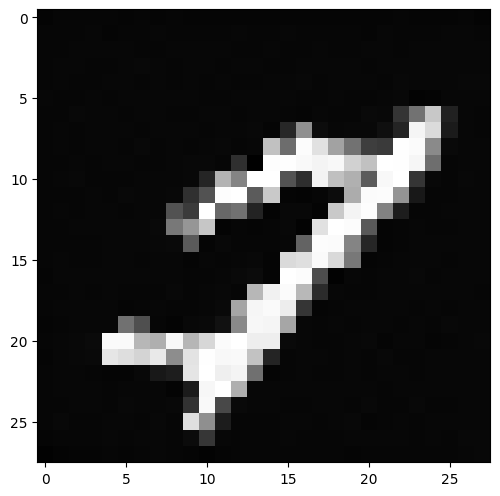

In [208]:
traj = torchdiffeq.odeint(
    forward_w_cbf,
    ic,
    torch.linspace(0, ts, num_steps, device=device),
    atol=1e-4,
    rtol=1e-4,
    method="dopri5",
)
grid = make_grid(
    traj[-1, :100].view([-1, 1, 28, 28]).clip(-1, 1),
    value_range=(-1, 1),
    padding=0,
    nrow=10,
)
img = ToPILImage()(grid)
plt.imshow(img)

## Library implementation: Class-Conditional

In [7]:
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 128
n_epochs = 10

trainset = datasets.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transforms.Compose(
        [transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))]
    ),
)

train_loader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, drop_last=True
)

In [8]:
#################################
#    Class Conditional CFM
#################################
sigma = 0.0
model = UNetModel(
    dim=(1, 28, 28), num_channels=32, num_res_blocks=1, num_classes=10, class_cond=True
).to(device)
optimizer = torch.optim.Adam(model.parameters())
FM = ConditionalFlowMatcher(sigma=sigma)
# Users can try target FM by changing the above line by
# FM = TargetConditionalFlowMatcher(sigma=sigma)
node = NeuralODE(model, solver="dopri5", sensitivity="adjoint", atol=1e-4, rtol=1e-4)

In [9]:
for epoch in range(n_epochs):
    for i, data in enumerate(train_loader):
        optimizer.zero_grad()
        x1 = data[0].to(device)
        y = data[1].to(device)
        x0 = torch.randn_like(x1)
        t, xt, ut = FM.sample_location_and_conditional_flow(x0, x1)
        vt = model(t, xt, y)
        loss = torch.mean((vt - ut) ** 2)
        loss.backward()
        optimizer.step()
        print(f"epoch: {epoch}, steps: {i}, loss: {loss.item():.4}", end="\r")

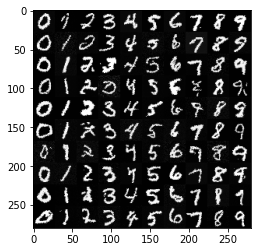

In [10]:
USE_TORCH_DIFFEQ = True
generated_class_list = torch.arange(10, device=device).repeat(10)
with torch.no_grad():
    if USE_TORCH_DIFFEQ:
        traj = torchdiffeq.odeint(
            lambda t, x: model.forward(t, x, generated_class_list),
            torch.randn(100, 1, 28, 28, device=device),
            torch.linspace(0, 1, 2, device=device),
            atol=1e-4,
            rtol=1e-4,
            method="dopri5",
        )
    else:
        traj = node.trajectory(
            torch.randn(100, 1, 28, 28, device=device),
            t_span=torch.linspace(0, 1, 2, device=device),
        )
grid = make_grid(
    traj[-1, :100].view([-1, 1, 28, 28]).clip(-1, 1),
    value_range=(-1, 1),
    padding=0,
    nrow=10,
)
img = ToPILImage()(grid)
plt.imshow(img)
plt.show()

## Test sample generation

In [171]:
import cvxpy as cp

gcl = torch.tensor([0], device=device)
ts = 10.0
num_steps = 10


def forward_wo_cbf(t, x, gcl=gcl):
    return model.forward(t / ts, x, gcl) / ts


def forward_w_cbf(t, x, gcl=gcl, classifier=classfier):
    flow_grad = model.forward(t / ts, x, gcl) / ts
    x_cp = x.clone().flatten(1).requires_grad_(True)
    out = classifier(x_cp)
    out.backward()
    clf_grad = x_cp.grad.cpu().numpy()
    cbf_v = []
    for i in range(x.size(0)):
        expert_v = flow_grad[i].flatten().detach().cpu().numpy()
        vv = cp.Variable(expert_v.shape)
        constr = [(clf_grad[i] @ vv) >= -0.1 * out[i].item()]
        prob = cp.Problem(cp.Minimize(cp.sum(cp.square(expert_v - vv))), constr)
        prob.solve()
        cbf_v.append(torch.tensor(vv.value).reshape(*flow_grad[i].shape).float())
    cbf_v = torch.stack(cbf_v).to(x.device)
    return cbf_v

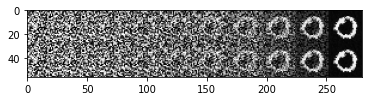

In [172]:
ic = torch.randn(len(gcl), 1, 28, 28, device=device)

traj_wo = torchdiffeq.odeint(
    forward_wo_cbf,
    ic,
    torch.linspace(0, ts, num_steps, device=device),
    atol=1e-4,
    rtol=1e-4,
    method="rk4",
)

traj_w = torchdiffeq.odeint(
    forward_w_cbf,
    ic,
    torch.linspace(0, ts, num_steps, device=device),
    atol=1e-4,
    rtol=1e-4,
    method="rk4",
)

grid_w = make_grid(traj_w[:, 0].clip(-1, 1), value_range=(-1, 1), padding=0, nrow=10)
grid_wo = make_grid(traj_wo[:, 0].clip(-1, 1), value_range=(-1, 1), padding=0, nrow=10)

grid = torch.cat((grid_wo, grid_w), dim=1)
img = ToPILImage()(grid)
plt.imshow(img)
plt.show()

## Naive Implementation

In [3]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [ ]:
# --------------------
# 1. Hyperparameters
# --------------------
batch_size = 128
lr = 3e-4
epochs = 200
device = "cuda" if torch.cuda.is_available() else "cpu"

# --------------------
# 2. MNIST Data
# --------------------
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)


class DoubleConv(nn.Module):
    """
    Two 3×3 convolutions + ReLU.
    """

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class Down(nn.Module):
    """
    Downscale with MaxPool2d, then apply DoubleConv.
    """

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x):
        x = self.pool(x)
        x = self.conv(x)
        return x


class Up(nn.Module):
    """
    Upscale, then concatenate skip connection, then DoubleConv.
    Here we use nearest-neighbor upsampling for simplicity.
    """

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x, skip):
        # x is the current (upsampled) feature
        # skip is the feature from the encoder (same spatial size after upsampling)
        x = self.up(x)  # e.g., 7×7 -> 14×14
        x = torch.cat([x, skip], dim=1)  # Concatenate along channels
        x = self.conv(x)
        return x


class UNet(nn.Module):
    """
    A minimal U-Net for 28x28 single-channel images.
    Input:  (batch, 2, 28, 28) => (x(t) + t-channel).
    Output: (batch, 1, 28, 28).
    """

    def __init__(self):
        super().__init__()
        # Encoder
        self.inc = DoubleConv(2, 32)  # initial conv (28×28 -> 28×28)
        self.down1 = Down(32, 64)  # (28->14)
        self.down2 = Down(64, 128)  # (14->7)

        # Bottleneck remains at 7×7
        self.bottleneck = DoubleConv(128, 128)

        # Decoder
        # We'll skip-connect with down1 (64-ch, 14×14) and inc (32-ch, 28×28)
        self.up2 = Up(128 + 64, 64)  # up from 7->14, skip from down1
        self.up1 = Up(64 + 32, 32)  # up from 14->28, skip from inc
        self.outc = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        # x shape: (batch, 2, 28, 28)
        # Encode
        x0 = self.inc(x)  # => (batch, 32, 28, 28)
        x1 = self.down1(x0)  # => (batch, 64, 14, 14)
        x2 = self.down2(x1)  # => (batch, 128, 7, 7)

        # Bottleneck
        bn = self.bottleneck(x2)  # => (batch, 128, 7, 7)

        # Decode
        x = self.up2(bn, x1)  # => (batch, 64, 14, 14)
        x = self.up1(x, x0)  # => (batch, 32, 28, 28)
        out = self.outc(x)  # => (batch, 1, 28, 28)
        return out


# Create the model
model = UNet().to(device)

# --------------------
# 4. Optimizer
# --------------------
optimizer = optim.Adam(model.parameters(), lr=lr)


# --------------------
# 5. Training Setup
# --------------------
def sample_time_and_noise(x, device):
    """
    Samples:
      - t ~ Uniform(0, 1)
      - z ~ N(0, I)
    Returns:
      t (batch_size, 1, 1, 1) for broadcasting
      z (same shape as x)
    """
    bsz = x.shape[0]
    t = torch.rand(bsz, 1, 1, 1, device=device)  # shape (bsz,1,1,1) so it can broadcast
    z = torch.randn_like(x, device=device)  # same shape as x
    return t, z


def get_linear_bridge(x0, z, t):
    """
    Linear bridging from x0 at t=0 to z at t=1:
      x(t) = (1 - t) * x0 + t * z
    Velocity:
      dx/dt = z - x0
    """
    x_t = (1.0 - t) * x0 + t * z
    vel_true = z - x0
    return x_t, vel_true


# --------------------
# 6. Training Loop
# --------------------
model.train()
for epoch in range(epochs):
    total_loss = 0.0
    for batch, _ in train_loader:
        # batch shape: (batch_size, 1, 28, 28)
        x0 = batch.to(device)  # (bsz, 1, 28, 28)
        image_size = x0.size(2)

        # Sample t and z
        t, z = sample_time_and_noise(x0, device=device)

        # Build x(t) and the true velocity
        x_t, vel_true = get_linear_bridge(x0, z, t)

        # Prepare input to the U-Net: concat [x_t, t_channel]
        # t_channel is shape (bsz,1,1,1), so we'll expand to (bsz,1,28,28) and concat
        t_rep = t.expand(-1, -1, image_size, image_size)  # => (bsz,1,28,28)
        input_unet = torch.cat([x_t, t_rep], dim=1)  # => (bsz, 2, 28, 28)

        # Forward pass: predict velocity
        vel_pred = model(input_unet)  # => (bsz, 1, 28, 28)

        # Compute MSE loss
        loss = ((vel_pred - vel_true) ** 2).mean()

        # Backprop
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x0.size(0)

    avg_loss = total_loss / len(train_loader.dataset)
    print(f"Epoch [{epoch + 1}/{epochs}] - Loss: {avg_loss:.4f}")


# --------------------
# 7. Sampling (Reverse Flow)
# --------------------
@torch.no_grad()
def sample_flow(model, num_samples=16, steps=50):
    """
    We start from x(1) ~ N(0,I) and solve
      dx/dt = -v(t, x)
    from t=1 down to t=0 with a naive Euler method.

    steps: number of discrete steps for the Euler integration
    """
    model.eval()

    # Start from Gaussian noise
    x = torch.randn(num_samples, 1, image_size, image_size, device=device)

    # We'll move from t=1 to t=0 in 'steps'
    ts = torch.linspace(1.0, 0.0, steps + 1, device=device)
    dt = -1.0 / steps

    for i in range(steps):
        t_i = ts[i].view(1, 1, 1, 1).to(device)
        t_i = t_i.expand(num_samples, 1, image_size, image_size)  # => (bsz,1,28,28)
        input_unet = torch.cat([x, t_i], dim=1)  # => (bsz,2,28,28)
        v = model(input_unet)  # => (bsz,1,28,28)
        x = x + dt * v  # Euler update

    return x


# --------------------
# 8. Visualize Generated Samples
# --------------------
def plot_samples(samples, title="Generated Samples"):
    # samples: (batch_size, 1, 28, 28)
    samples = samples.cpu().numpy()
    fig, axes = plt.subplots(1, len(samples), figsize=(len(samples) * 1.5, 2))
    for i, ax in enumerate(axes):
        ax.imshow(samples[i, 0], cmap="gray")
        ax.axis("off")
    plt.suptitle(title)
    plt.show()


# Generate samples
generated = sample_flow(model, num_samples=8, steps=50)
plot_samples(generated, "Flow Matching U-Net Samples")